In [1]:
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from decimal import Decimal, ROUND_CEILING

### Load reference

In [2]:
REF = [
    (
        "HEK293T-HCT116_abundanceTMT.genes",
        "HEK293T-HCT116_abundanceTMT.background",
        "Differential\nprotein abundance\n(Zuniga et al. 2024)",
    ),
    (
        "HEK293T-HCT116_RNA.genes",
        "HEK293T-HCT116_RNA.background",
        "Differential\nRNA expression\n(Jin et al. 2023)",
    ),
    (
        "HEK293T-HCT116_stress.genes",
        "HEK293T-HCT116_stress.background",
        "Differential\nnutrient-stress response\n(An et al. 2020)",
    )
]

In [3]:
def load_gene_set(name):
    with open(f"../../result/reference/{name}", "r") as handle:
        return set(line.strip() for line in handle if line.strip())

gold_list = [load_gene_set(filename) for filename, _, _ in REF]
background_list = [load_gene_set(filename) for _, filename, _ in REF]
n_ref = len(gold_list)

### Load proteins

In [4]:
PROTEIN_METHODS = [
    (
        "AP degree",
        "../../result/HEK293T_HCT116/ranking/AP-MS_degree.ranking"
    ),
    (
        "SEC abundance",
        "../../result/HEK293T_HCT116/ranking/SEC-MS_abd.ranking"
    ),
    (
        "SEC degree",
        "../../result/HEK293T_HCT116/ranking/SEC-MS_degree.ranking"
    ),
    (
        "ProMERGE",
        "../../result/HEK293T_HCT116/cca/promergeclub_HCT116anchor_HEK293T.cca"
    ),
    (
        "ProMERGE-disentangle",
        "../../result/HEK293T_HCT116/coemb/promergeclub_HCT116anchor/HEK293T/HEK293T_specific_score.tsv"
    ),
]

In [5]:
label_list = [label for label, _ in PROTEIN_METHODS]
n_label = len(label_list)
promerge_idx = label_list.index("ProMERGE-disentangle")

In [6]:
def load_model_score(name):
    frame = pd.read_csv(name, sep="\t", index_col=0)
    return frame["specific_score"].astype(float)


def load_other_score(name):
    frame = pd.read_csv(name, sep="\t")
    return frame.set_index("gene")["score"].astype(float)


def load_score(name):
    if name.endswith("specific_score.tsv"):
        return load_model_score(name)
    else:
        return load_other_score(name)

In [7]:
# gene universe
gene_sets = [
    set(pd.read_csv(
        f"../../result/HEK293T_HCT116/input/{modality}-{context}.tsv",
        sep="\t", index_col=0, usecols=[0]
    ).index)
    for context in ["HCT116", "HEK293T"]
    for modality in ["BioPlex", "SECMX"]
]
gene_list = sorted(set.intersection(*gene_sets))
n_gene = len(gene_list)
gene_index = pd.Index(gene_list)

In [8]:
score_list = [
    load_score(name)
    for _, name in PROTEIN_METHODS
]

score_mat = np.vstack([
    np.nan_to_num(series.reindex(gene_index).values.astype(np.float64))
    for series in score_list
])

label_mat = np.vstack([
    gene_index.isin(gold_standard).astype(np.int8)
    for gold_standard in gold_list
])

# each reference is scored only on its background genes
valid_mat = np.vstack([
    gene_index.isin(background).astype(np.int8)
    for background in background_list
])

auc_emb = np.empty((n_label, n_ref))
for ii in range(n_label):
    for rr in range(n_ref):
        keep = valid_mat[rr].astype(bool)
        auc_emb[ii, rr] = roc_auc_score(
            label_mat[rr][keep],
            score_mat[ii][keep]
        )

In [9]:
pd.DataFrame(
    auc_emb,
    index=label_list,
    columns=[f for f , _, _ in REF]
)

,HEK293T-HCT116_abundanceTMT.genes,HEK293T-HCT116_RNA.genes,HEK293T-HCT116_stress.genes
AP degree,0.532386,0.562180,0.512524
SEC abundance,0.655986,0.574611,0.492190
SEC degree,0.543102,0.538046,0.544974
ProMERGE,0.633110,0.606079,0.578649
ProMERGE-disentangle,0.658386,0.626487,0.591835


### Bootstrap

In [10]:
def sort_by_score(score, label_mat, valid_mat):
    """
    Sort one method's units by score once and record where each block
    of tied scores starts.
    """
    order = np.argsort(score, kind="stable")
    score_sorted = score[order]
    grp_start = np.flatnonzero(
        np.r_[True, score_sorted[1:] != score_sorted[:-1]]
    )
    return label_mat[:, order], valid_mat[:, order], grp_start


def weighted_auroc(label_sorted, weight_sorted, grp_start):
    """
    AUROC in Mann-Whitney U form, each unit counted weight times and
    tied scores sharing half credit.
    """
    pos = weight_sorted * label_sorted
    neg = weight_sorted - pos
    pos_g = np.add.reduceat(pos, grp_start)
    neg_g = np.add.reduceat(neg, grp_start)
    below = np.cumsum(neg_g) - neg_g
    u = np.dot(pos_g, below + 0.5 * neg_g)
    return float(u / (pos_g.sum() * neg_g.sum()))


def bootstrap_auroc(label_sorted, valid_sorted, grp_start, n_boot, rng):
    """
    Resample one method's units with replacement and recompute its AUROC
    against every reference. Each method draws on its own.
    """
    n_ref, n_unit = label_sorted.shape
    auc = np.empty((n_boot, n_ref))
    for bb in tqdm(range(n_boot)):
        weight = np.bincount(
            rng.integers(0, n_unit, n_unit), minlength=n_unit
        ).astype(np.float64)
        for rr in range(n_ref):
            auc[bb, rr] = weighted_auroc(
                label_sorted[rr], weight * valid_sorted[rr], grp_start
            )
    return auc

In [11]:
N_BOOT = 10000
rng = np.random.default_rng(1)
auc_boot = np.empty((N_BOOT, n_label, n_ref))

for ii, label in enumerate(label_list):
    label_sorted, valid_sorted, group_start = sort_by_score(
        score_mat[ii], label_mat, valid_mat
    )

    # check that unit weights reproduce roc_auc_score
    check = [
        weighted_auroc(
            label_sorted[rr],
            valid_sorted[rr].astype(np.float64),
            group_start,
        )
        for rr in range(n_ref)
    ]
    assert np.allclose(check, auc_emb[ii]), label

    auc_boot[:, ii, :] = bootstrap_auroc(
        label_sorted, valid_sorted, group_start, N_BOOT, rng
    )

100%|██████████| 10000/10000 [00:03<00:00, 3085.00it/s]


In [12]:
# CI from bootstrap
ci_lo = np.percentile(auc_boot, 2.5, axis=0)
ci_hi = np.percentile(auc_boot, 97.5, axis=0)

# stat test from bootstrap, unpaired: each method has its own draws
stat_row_list = []
for rr, (ref_name, _, _) in enumerate(REF):
    for mm, method_label in enumerate(label_list):
        
        boot_a = auc_boot[:, mm, rr]
        boot_b = auc_boot[:, promerge_idx, rr]
        delta_boot = boot_a - boot_b
        delta_obs = auc_emb[mm, rr] - auc_emb[promerge_idx, rr]

        p_lower = (np.sum(delta_boot >= 0) + 1) / (N_BOOT + 1)
        p_upper = (np.sum(delta_boot <= 0) + 1) / (N_BOOT + 1)

        se_delta = np.hypot(boot_a.std(ddof=1), boot_b.std(ddof=1))
        z = delta_obs / se_delta
        
        stat_row_list.append({
            "reference": ref_name,
            "method": method_label,
            "auc": auc_emb[mm, rr],
            "n_boot": N_BOOT,
            "ci_lower": ci_lo[mm, rr],
            "ci_upper": ci_hi[mm, rr],
            "delta_auc": delta_obs,
            "p_boot": min(2 * min(p_lower, p_upper), 1.0),
            "z": z,
            "p_z": 2 * norm.sf(abs(z)),
        })
stat_df = pd.DataFrame(stat_row_list)
stat_df.to_csv("./figS8_benchmark_protein_vs_raw.tsv", sep="\t", index=False)

In [13]:
# p-value annotation: 2 decimal places, always rounded up
def format_p_z(p):
    value = Decimal(str(p))
    if value.is_nan():
        return "nan"
    if value == 0:
        return "0.00e0"

    exponent = value.adjusted()
    mantissa = value.scaleb(-exponent).quantize(
        Decimal("0.01"), rounding=ROUND_CEILING
    )
    if mantissa == Decimal("10.00"):
        mantissa = Decimal("1.00")
        exponent += 1
    return f"{mantissa:.2f}e{exponent}"

pz_lookup = {
    (row["reference"], row["method"]): format_p_z(row["p_z"])
    for _, row in stat_df.iterrows()
}

### plot

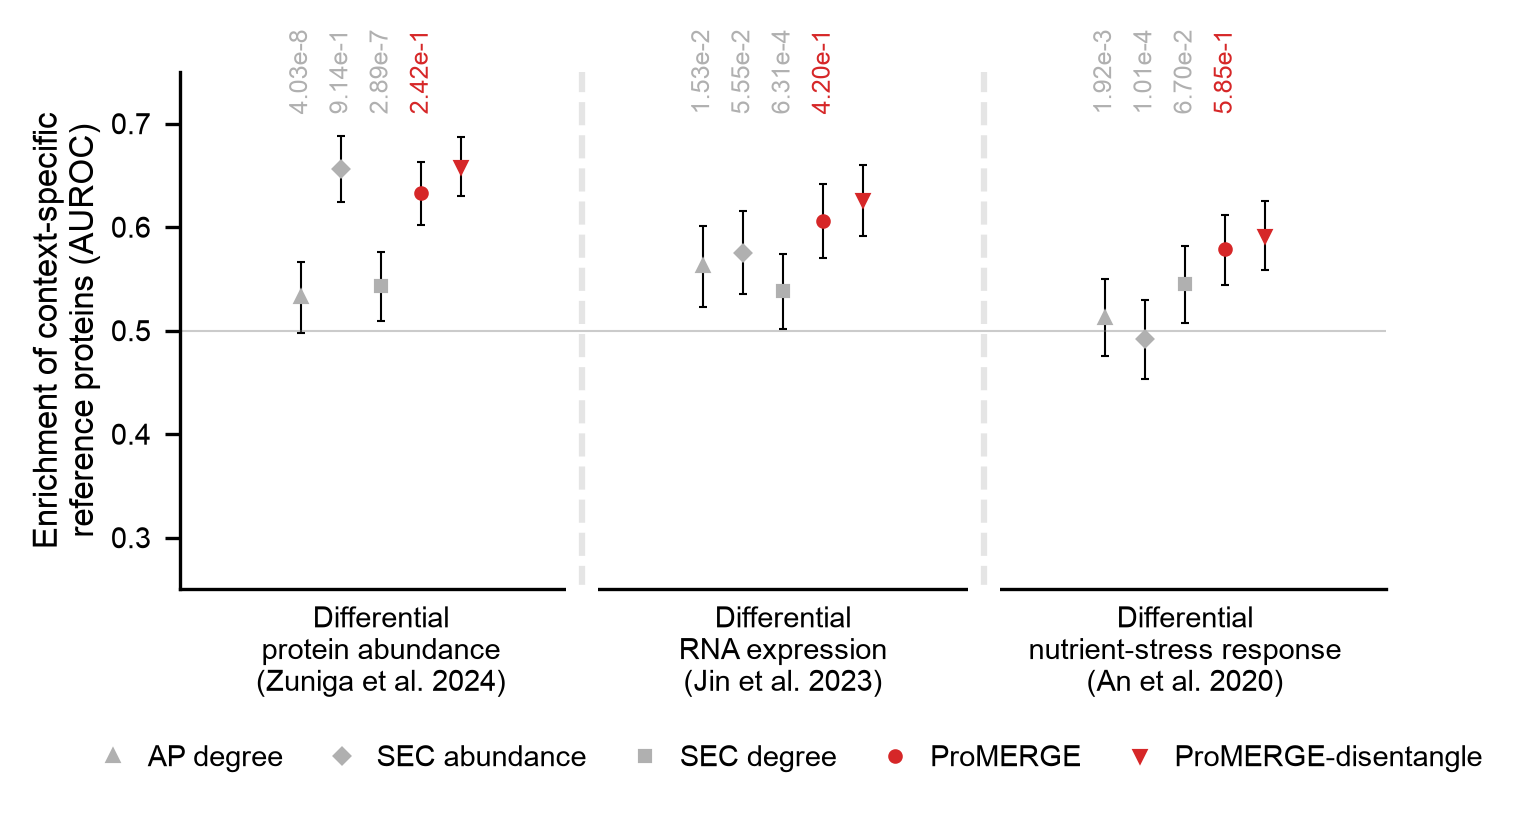

In [14]:
color_list = [
    "#b0b0b0", "#b0b0b0", "#b0b0b0",
    "tab:red", "tab:red",
]
marker_list = [
    "^", "D", "s",
    "o", "v"
]

row_span = (n_label - 1) * 0.1
row_y = np.arange(1, n_ref + 1)
method_dy = np.arange(n_label) * 0.1
pad = (1 - row_span) / 2

# init plot
plt.style.use("/home/jig049/misc/style.mplstyle")
fig, ax = plt.subplots(figsize=(6, 2.5), dpi=300)
fig.subplots_adjust(left=0.30, right=0.97, bottom=0.30, top=0.99)

for ii, method_label in enumerate(label_list):
    x = row_y + method_dy[ii]
    ax.errorbar(
        x=x,
        y=auc_emb[ii],
        yerr=np.vstack([
            auc_emb[ii] - ci_lo[ii],
            ci_hi[ii] - auc_emb[ii]
        ]),
        color=color_list[ii],
        marker=marker_list[ii],
        linestyle="",
        ms=2.5,
        ecolor="black",
        barsabove=False,
        elinewidth=0.5,
        capsize=1,
        capthick=0.5,
        label=method_label,
    )
    
    # p_z annotation
    if ii == promerge_idx:
        continue
    for rr, (ref_name, _, _) in enumerate(REF):
        ax.text(
            x[rr],
            0.75,
            pz_lookup[(ref_name, method_label)],
            fontsize=6,
            rotation=90,
            va="center",
            ha="center",
            color=color_list[ii],
        )

# line for AUROC=0.5
ax.hlines(
    0.5,
    xmin=0,
    xmax=n_ref + 1,
    linestyles="-",
    color="tab:grey",
    alpha=0.4,
    lw=0.5,
)

# axis and tick
ax.set_ylim([0.25, 0.75])
ax.set_xlim([row_y[0] - pad, row_y[-1] + row_span + pad])
ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7])
ax.set_xticks(row_y + row_span / 2, labels=[n for _, _, n in REF])
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y")
ax.set_ylabel("Enrichment of context-specific\nreference proteins (AUROC)", labelpad=2, fontsize=8)
ax.spines[["right", "top"]].set_visible(False)

# vertical line and white gap in x-axis to separate group
sep_x = row_y[1:] - pad
ax.vlines(sep_x, ymin=0.25, ymax=0.75, linestyles="--", color="tab:grey", alpha=0.2)
trans = ax.get_xaxis_transform()
gap = 0.08
for xx in sep_x:
    ax.plot(
        [xx - gap / 2, xx + gap / 2],
        [0, 0],
        transform=trans,
        color="white",
        lw=2.0,
        solid_capstyle="butt",
        clip_on=False,
        zorder=10,
    )

# legend
handles, labels = ax.get_legend_handles_labels()
handles = [h[0] for h in handles]
ax.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=5,
    frameon=False,
    handletextpad=0.2,
    columnspacing=1.0,
    labelspacing=0.3,
)

plt.savefig("./figS8_benchmark_protein_vs_raw.pdf", bbox_inches="tight", transparent=True)